
# Coding Report

# Problem Description

This report decomstrate 2 methods for evaluating numerical solution of equations.

## Algorithm

For a given equation in matrix form

$$
F(X) = 0, X\in \mathbb{R}{n}, F(X)\in \mathbb{R}m
$$

The **fixed point method** tries to transform the equations of the form 

$$
G(X) = X , X\in \mathbb{R}{n}, F(X)\in \mathbb{R}m
$$

for example, a simplest form can be obtained by letting $G(X) = F(X)+X$, but this may not perform the best. If for an initial value $X_0$ and its neiborhood $B(X_0)$, $G(X)$ satisfies the Lipschtz condition

$$||G(X) - G(Y)||\leqslant u ||X - Y||, u<1, \forall X,Y\in B(X_0)$$

then by the Image Compression Principle, for the iteration formula

$$\color{purple}X_{k+1} = G(X_k)$$

and the expected convergence point $X^*$, which is the zero point of $F(X)$ such that $G(X^*) = X^*$ , we'll have

$$||X_{k+1}- X^*|| = ||G(X_{k}) - G(X^*)||\leqslant u^k ||X_0-X^*|| \to 0\qquad\text{ as } k\to +\infty
$$

This is a sufficient condition of the convergence of the purple formula.

The **Newton's Method** is based on the intuition that a function will decrease along its derivative, and can also be intepreted into a fixed point method. It's formula is

$$ X_{k+1} = X_k - J_k(X_k)^{-1}F(X_k) $$

which can come from the Taylor sequence around the zero point $X^*$:

$$ F(X) = F(X^*) + J(X^*)(X-X^*) + o(||X-X^*||) $$

Let $G(X) = X - J(X)^{-1} F(X) $, we can find that $X^*$ satisfies $G(X^*)=X^*$, indicating that Newton's method is also a kind of fixed point method.

For the given equations

$$ x_1^2 - 10 x_1 + x_2 ^2 +8 =0,\quad x_1x_2^2+x_1-10x_2+8=0$$

by let

$$ x_1=\dfrac{x_1^2+x_2^2+8}{10},\quad x_2=\dfrac{x_1x_2^2+x_1+8}{10} $$

and let 

$$ X= \begin{bmatrix} x_1\\x_2\end{bmatrix}, G(X)=\begin{bmatrix} \dfrac{x_1^2+x_2^2+8}{10}\\\dfrac{x_1x_2^2+x_1+8}{10}\end{bmatrix}, F(X) = \begin{bmatrix}x_1^2 - 10 x_1 + x_2 ^2 +8\\ x_1x_2^2+x_1-10x_2+8\end{bmatrix} $$

we can write down the iteration formula for these 2 methods:

**Fixed point method**:

$$
\begin{bmatrix} x_1^{(k+1)}\\x_2^{(k+1)}\end{bmatrix} = \begin{bmatrix} \dfrac{(x_1^{(k)})^2+(x_2^{(k)})^2+8}{10}\\\dfrac{x_1^{(k)}(x_2^{(k)})^2+x_1^{(k)}+8}{10}\end{bmatrix} 
$$

**Newton's Method**:

$$
J(X) = \begin{bmatrix}-10+2x_1&2x_2\\1+x_2^2&-10+2x_1x_2\end{bmatrix},\qquad\begin{bmatrix} x_1^{(k+1)}\\x_2^{(k+1)}\end{bmatrix} = \begin{bmatrix} x_1^{(k)}\\x_2^{(k)}\end{bmatrix} - J(X_k)^{-1}F(X_k)
$$

The inverse for 2D matrix is 

$$J(X)^{-1}=\dfrac{1}{100-20x_1-2x_2-20x_1x_2+4x_1^2x_2-20x_2^3}\begin{bmatrix}-10+2x_1x_2&-2x_2\\-1-x_2^2&-10+2x_1\end{bmatrix}$$

# Result

To measure the efficiency of both methods, we ran each method $10^{k},k\in\{1,2,3,4,5\}$ times and recorded the time. The following images show the trend of times as $n$ increases, apparently it is linear and the tangency is listed in the following table:

| Method | Starting Point | Average Time | Result | Iteration |
| :----: | :------------: | :----: | :----: | :-------: |
| Fixed point | $(3, 2)$ | $1.1\times 10^{-4}$ | $(1.000000, 1.000000)$   | $20$   | 
| Newton | $(3, 2)$ | $7.1\times 10^{-5}$ | $(2.193439 3.020466)$   | $5$   | 
| Fixed point | $(-2, 1)$ | $8.6\times 10^{-4}$ | $(1.000000, 1.000000)$   | $15$   | 
| Newton | $(-2, 1)$ | $7.1\times 10^{-5}$ | $(1.000000, 1.000000)$   | $5$   | 

**Table 1: Information of each method**

See the appendix for the details.

The following graphs shows the increse of time and the convergence path:

![Time1](./Time1.png)
**Image 1: Time cost if start from $(3,2)$**

![Time2](./Time2.png)
**Image 2: Time cost if start from $(-2,1)$**

![Iter1](./Iter1.png)
**Image 3: Convergence path if start from $(3,2)$**

![Iter2](./Iter2.png)
**Image 4: Convergence path if start from $(-2, 1)$**



# Analysis

From the results above, we can reach the following conclusions:

- Newton's method is faster and costs less iterations than the fixed point method we used (at least in this problem)
- Although started from the same initial point, if we adopt distinct iteration formula, the convergence point still may be distinct. Especially when the function has multiple zero points.
- Even if differenct methods converge to the same point, the convergence paths may be distinct and it may not be always towards the solution.
- If the initial value is not taken properly, the process may diverge.

The following images shows the last case:

![Image3](./Iter3.png)
**Image 4: A diverging iteration sequence**

# Collaboration
No collaboration on this project.

# Academic Integrity
On my personal intergrity as a student and member of the UCD community, I have not given, or received and unauthorized assitance on this assignment.

# Appendix

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from ttictoc import tic, toc

In [2]:
f1 = lambda x: x[0]**2-10*x[0]+x[1]**2+8
f2 = lambda x: x[0]*x[1]**2+x[0]-10*x[1]+8
g1 = lambda x: 0.1 * (x[0]**2+x[1]**2+8)
g2 = lambda x: 0.1 * (x[0]*x[1]**2+x[0]+8)

In [3]:
Jdet = lambda x: 100-20*x[0]-2*x[1]-20*x[0]*x[1]+4*x[0]**2*x[1]-2*x[1]**3
Jinv = lambda x: np.array([[-10+2*x[0]*x[1],-2*x[1]],[-1-x[1]**2,-10+2*x[0]]]) / Jdet(x)

F = lambda x: np.array([f1(x), f2(x)])
FG = lambda x: np.array([g1(x), g2(x)])
NG = lambda x: x - Jinv(x) @ F(x)

In [4]:
def solve_fixed_point(G, x0, tol, max_iter, log=False):
    x1 = x0.copy()
    x0 = np.ones_like(x1) * np.inf
    if log:
        logs = [list(x1.copy())]
    i = 0
    while np.linalg.norm(x1 - x0, 1) > tol and i < max_iter:
        x0 = x1
        x1 = G(x0)
        if log:
            logs.append(x1.copy()) # type: ignore
        i += 1
    return x1, i, np.array(logs) if log else None # type: ignore

In [8]:
def run(init, save):
      x_init = init #np.array([3, 2])
      res1, it1, logs1 = solve_fixed_point(FG, x_init, 1e-6, 1000, True)
      res2, it2, logs2 = solve_fixed_point(NG, x_init, 1e-6, 1000, True)
      print(f"Initial value: {x_init}")
      print(f"Results: [Fixed point] {res1}  [Newton] {res2}")
      print(f"Iteration: [Fixed point] {it1}  [Newton] {it2}")

      n = 100
      xs = np.linspace(-3, 5, n)
      ys = np.linspace(-3, 5, n)
      X, Y = np.meshgrid(xs, ys)
      Z = [[np.sqrt(f1([X[i, j], Y[i, j]])**2 + f2([X[i, j], Y[i, j]]) ** 2) 
            for i in range(n)] for j in range(n)]
      levels = np.linspace(np.min(Z), np.max(Z), 128)

      plt.figure()
      plt.contourf(X, Y, Z, levels=levels)
      plt.colorbar()
      plt.title(f"Norm of $F(X)$, start from {init}")
      plt.xlabel("$x_1$")
      plt.ylabel("$x_2$")

      plt.scatter([2.19344, 1], [3.02047, 1], label="Zero points", color="purple")

      plt.plot(logs1[:, 0], logs1[:, 1], label="Fixed point")
      plt.plot(logs2[:, 0], logs2[:, 1], label="Newton's method")

      plt.legend()
      plt.savefig(save, dpi=450)
      plt.show()

Initial value: [3 2]
Results: [Fixed point] [1.00000028 1.00000028]  [Newton] [2.19343942 3.02046647]
Iteration: [Fixed point] 20  [Newton] 5


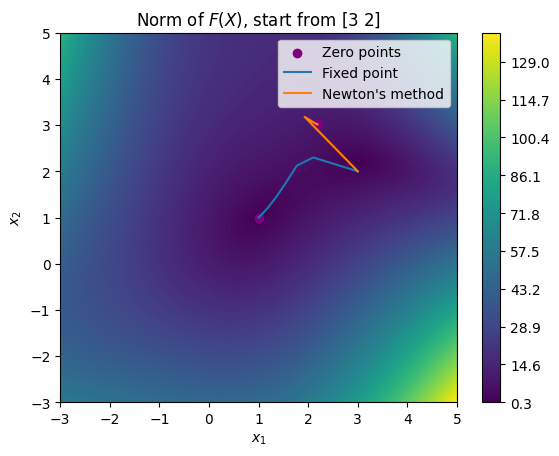

Initial value: [-2  1]
Results: [Fixed point] [0.99999979 0.99999979]  [Newton] [1. 1.]
Iteration: [Fixed point] 15  [Newton] 5


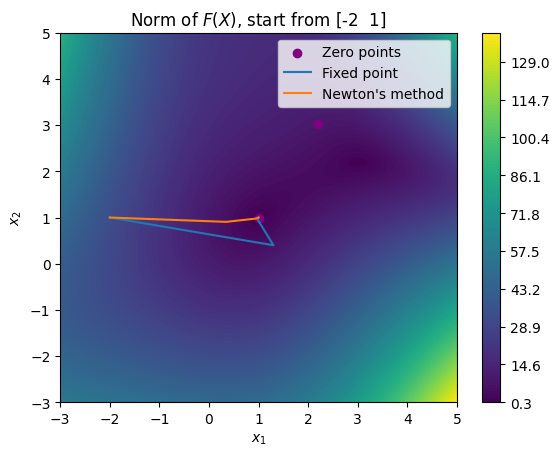

In [22]:
run(np.array([3, 2]), "Iter1.png")
run(np.array([-2, 1]), "Iter2.png")

C:\Users\taken\AppData\Local\Temp\ipykernel_54888\2993300979.py:4: RuntimeWarning: overflow encountered in double_scalars
  g2 = lambda x: 0.1 * (x[0]*x[1]**2+x[0]+8)
C:\Users\taken\AppData\Local\Temp\ipykernel_54888\2993300979.py:3: RuntimeWarning: overflow encountered in double_scalars
  g1 = lambda x: 0.1 * (x[0]**2+x[1]**2+8)
C:\Users\taken\AppData\Local\Temp\ipykernel_54888\2979540131.py:7: RuntimeWarning: invalid value encountered in subtract
  while np.linalg.norm(x1 - x0, 1) > tol and i < max_iter:


Initial value: [3 3]
Results: [Fixed point] [inf inf]  [Newton] [2.19343942 3.02046647]
Iteration: [Fixed point] 11  [Newton] 4


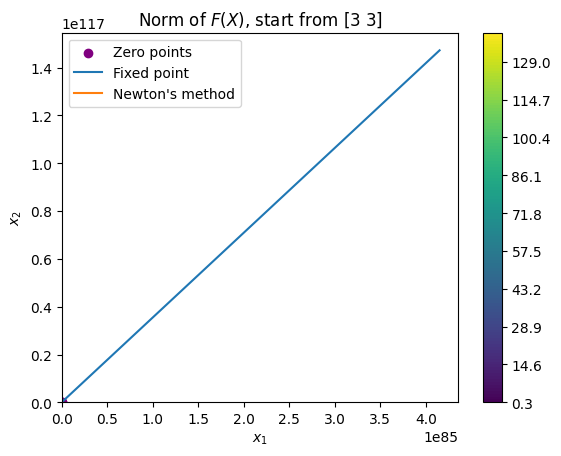

In [21]:
run(np.array([3, 3]), "Iter3.png")

In [15]:
def meter_time(init, ns, save):
    t1s = []
    for n in tqdm(ns):
        tic()
        for _ in range(n):
            solve_fixed_point(FG, init, 1e-6, n)
        t1s.append(toc())
    t2s = []
    for n in tqdm(ns):
        tic()
        for _ in range(n):
            solve_fixed_point(NG, init, 1e-6, n)
        t2s.append(toc())

    plt.figure()
    plt.plot(ns, t1s, label="Fixed point method")
    plt.plot(ns, t2s, label="Newton's method")
    plt.title(f"Solving time, start from {init}")
    plt.xlabel("$n$")
    plt.ylabel("time (s)")
    plt.legend()
    plt.savefig(save, dpi=450)
    plt.show()

    return t1s, t2s

100%|██████████| 5/5 [00:07<00:00,  1.59s/it]


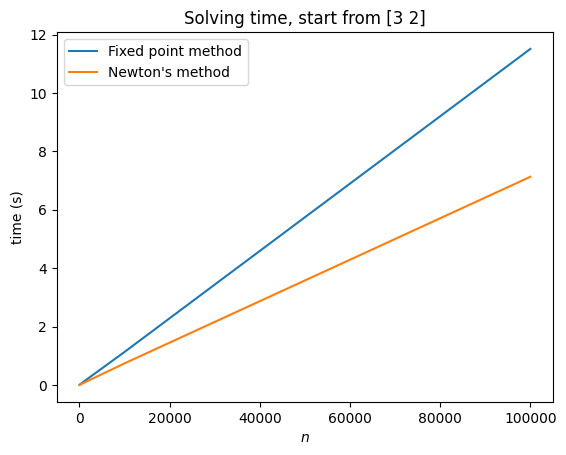

[0.000990999978967011, 0.01262050005607307, 0.11865650000981987, 1.1293248999863863, 11.507942000054754] 
 [0.0007882000645622611, 0.006182399927638471, 0.07461250002961606, 0.7380325999110937, 7.128359500085935]


100%|██████████| 5/5 [00:07<00:00,  1.58s/it]


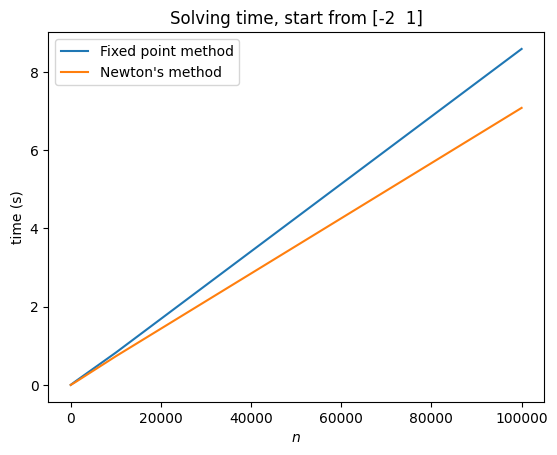

[0.0009346000151708722, 0.009908600011840463, 0.0864280000096187, 0.8252908999565989, 8.590299199917354] 
 [0.0007582999533042312, 0.006954299984499812, 0.068160800030455, 0.7321093999780715, 7.083371199900284]


In [19]:
ns = [10 ** i for i in range(1, 6)]
t1s, t2s = meter_time(np.array([3, 2]), ns, "Time1.png")
print(t1s, "\n", t2s)
t1s, t2s = meter_time(np.array([-2, 1]), ns, "Time2.png")
print(t1s,"\n", t2s)